# Assignment 2: TF-IDF vs. Sentence Embeddings on IMDB

Three models are compared on the same data, for **classification** (Task 1) and **retrieval** (Task 2).

| Model | Representation | Classifier |
|---|---|---|
| A | `TfidfVectorizer` (fit on the training split only) | Logistic Regression |
| B | `sentence-transformers/all-MiniLM-L6-v2` | Logistic Regression |
| C | `BAAI/bge-small-en-v1.5` | Logistic Regression |

All logic is in the `exercise2/` package. This notebook only imports it and runs it:

- `config.py`: seed, sample sizes, model names and query prefixes, the 10 queries
- `data.py`: random, class-balanced IMDB sample
- `features.py`: TF-IDF and embedding feature builders (each one is timed)
- `classify.py`: Logistic Regression, accuracy and macro-F1
- `retrieve.py`: cosine ranking and precision@10
- `checks.py`: sanity checks (sampling, leakage, prefixes, queries)

## Model choice

**B: `all-MiniLM-L6-v2`** (22M params, 384-dim). This is an older symmetric model, distilled from MiniLM and trained on about 1B sentence pairs. Its card says no prefix or instruction is needed, so queries and reviews are encoded the same way. It is the standard small baseline and is very fast on CPU.

**C: `BAAI/bge-small-en-v1.5`** (33M params, 384-dim). This is a newer model trained with contrastive pre-training plus fine-tuning for retrieval. It sits well above MiniLM on the MTEB leaderboard while staying small enough for a laptop. Its card recommends the instruction `"Represent this sentence for searching relevant passages: "` for short retrieval queries and no prefix for passages. We add it to the 10 queries only, not to the reviews. Classification features use the reviews with no prefix.

**MTEB columns used:** for Task 1 we looked at the **Classification** column. That column includes `ImdbClassification`, where bge-small scores higher than MiniLM. For Task 2 we looked at the **Retrieval** column, where bge-small is much stronger because it was trained for asymmetric query→passage search. Together the two models compare an older symmetric training recipe with a newer retrieval-trained one at roughly the same size.

In [ ]:
%load_ext autoreload
%autoreload 2
import sys, os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("."))
import datasets, transformers
datasets.disable_progress_bars()
transformers.logging.set_verbosity_error()

import pandas as pd
from exercise2 import config
from exercise2.data import load_imdb_sample
from exercise2.features import build_tfidf, build_embeddings
from exercise2.classify import train_and_evaluate
from exercise2.retrieve import evaluate_retrieval, top_result
from exercise2 import checks
pd.set_option("display.max_colwidth", 200)

## Data: balanced random sample (seed 42)

In [2]:
X_train, y_train, X_test, y_test, sample_idx = load_imdb_sample(return_indices=True)
print(f"train: {len(X_train)}  label counts: {pd.Series(y_train).value_counts().to_dict()}")
print(f"test : {len(X_test)}  label counts: {pd.Series(y_test).value_counts().to_dict()}")

train: 1000  label counts: {0: 500, 1: 500}
test : 500  label counts: {0: 250, 1: 250}


## Feature building (timed)
The embedding times include loading the model and encoding 1,500 reviews on CPU with `max_seq_length = 256`.

In [3]:
features = {"A": build_tfidf(X_train, X_test)}
for key, spec in config.EMBEDDING_MODELS.items():
    features[key] = build_embeddings(spec["name"], X_train, X_test, query_prefix=spec["query_prefix"])

names = {"A": "TF-IDF", **{k: v["name"].split("/")[-1] for k, v in config.EMBEDDING_MODELS.items()}}
for k, f in features.items():
    print(f"{k} ({names[k]}): train {f['train'].shape}, build time {f['seconds']:.1f}s")

A (TF-IDF): train (1000, 8944), build time 0.1s
B (all-MiniLM-L6-v2): train (1000, 384), build time 13.6s
C (bge-small-en-v1.5): train (1000, 384), build time 25.6s


## Task 1: Classification

In [4]:
clf_results = {k: train_and_evaluate(f["train"], y_train, f["test"], y_test) for k, f in features.items()}
clf_table = pd.DataFrame({
    "model": [f"{k}: {names[k]}" for k in features],
    "accuracy": [clf_results[k]["accuracy"] for k in features],
    "macro_F1": [clf_results[k]["macro_f1"] for k in features],
    "feature_time_s": [features[k]["seconds"] for k in features],
}).round(3)
clf_table

,model,accuracy,macro_F1,feature_time_s
0,A: TF-IDF,0.834,0.834,0.076
1,B: all-MiniLM-L6-v2,0.782,0.782,13.603
2,C: bge-small-en-v1.5,0.918,0.918,25.557


## Task 2: Retrieval (precision@10 over 500 test reviews)

In [5]:
ret_results = {k: evaluate_retrieval(f["encode_queries"], f["test"], y_test, config.QUERIES)
               for k, f in features.items()}
per_query = ret_results["A"]["per_query"][["query", "wants"]].copy()
for k in features:
    per_query[f"{k}: {names[k]}"] = ret_results[k]["per_query"]["P@10"].values
per_query.index = range(1, len(per_query) + 1)
per_query

,query,wants,A: TF-IDF,B: all-MiniLM-L6-v2,C: bge-small-en-v1.5
1,a heartwarming film I would happily watch again,positive,0.9,0.8,1.0
2,brilliant performances and a deeply moving story,positive,0.7,0.7,1.0
3,one of the best movies I have ever seen,positive,0.5,0.7,1.0
4,"funny, charming and highly recommended",positive,0.9,0.6,1.0
5,terrible acting and a boring plot,negative,1.0,1.0,1.0
6,"a complete waste of time, I wanted my money back",negative,0.9,0.7,1.0
7,poorly written and badly directed,negative,0.7,1.0,1.0
8,"dull, predictable and a huge disappointment",negative,0.8,0.9,1.0
9,"not bad at all, much better than I expected",positive,0.3,0.3,0.9
10,I expected a great film but it fell flat,negative,0.6,0.7,0.9


In [6]:
pd.DataFrame({"model": [f"{k}: {names[k]}" for k in features],
              "mean_P@10": [ret_results[k]["mean_p_at_k"] for k in features]}).round(3)

,model,mean_P@10
0,A: TF-IDF,0.73
1,B: all-MiniLM-L6-v2,0.74
2,C: bge-small-en-v1.5,0.98


### Hard queries (9 and 10): top result for each model

In [7]:
for qi in (8, 9):
    q, want = config.QUERIES[qi]
    print(f"\n=== Query {qi+1}: '{q}'  (wants {config.LABEL_NAMES[want]}) ===")
    for k in features:
        r = top_result(ret_results[k], qi, X_test, y_test)
        flag = "✓" if r["label"] == config.LABEL_NAMES[want] else "✗"
        print(f"\n[{k}: {names[k]}] {flag} label={r['label']}  cos={r['score']:.3f}\n{r['text']}")


=== Query 9: 'not bad at all, much better than I expected'  (wants positive) ===

[A: TF-IDF] ✗ label=negative  cos=0.146
Being a long-time fan of Japanese film, I expected more than this. I can't really be bothered to write to much, as this movie is just so poor. The story might be the cutest romantic little something ever, pity I couldn't stand the awful acting, the mess they called pacing, and the standard "quirky" Japanese story. If you've noticed how many Japanese movies use characters, plots and twists that see...

[B: all-MiniLM-L6-v2] ✗ label=negative  cos=0.413
My expectations were high after seeing the trailer. They were even higher when i saw the movie had the same director as independance day and godzilla. The special effects in independence day were much better then in this movie. The whole movie I was waiting for the spiders to show up. The rest of the storyline was really boring. And when the spiders came, they had a very amateuristic look, like th...

[C: bge-small-en-

## Sanity checks
Each check asserts, so the notebook stops if any of them fails.

1. The sample is random and balanced, and it is not the first N rows (the first 1,000 IMDB training rows are all negative).
2. TF-IDF is fit on the training split only, and no word that appears only in the test set enters the vocabulary.
3. The query prefix goes on queries only. MiniLM's card asks for no prefix. bge-v1.5's card says: *"In all cases, no instruction needs to be added to passages."* Re-encoding reviews with no prefix must give back the stored vectors.
4. Classification and retrieval use the same review vectors (the very same array object), so each review is embedded once per model.
5. Classification is scored on the 500 held-out test reviews.
6. The 10 queries match the assignment word for word, and each intent maps to the right label (0 = `neg`, 1 = `pos`).

In [8]:
checks.check_sample(y_train, y_test, sample_idx)
checks.check_tfidf_no_leakage(features["A"], X_train, X_test)
for k in config.EMBEDDING_MODELS:
    print(f"{k}: query prefix = {config.EMBEDDING_MODELS[k]['query_prefix']!r}")
    checks.check_no_prefix_on_reviews(features[k], X_test)
for k in features:
    assert ret_results[k]["doc_vecs"] is features[k]["test"]
    assert features[k]["test"].shape[0] == len(y_test) == config.N_TEST
print("OK: retrieval reuses the same test vectors used for classification (500 held-out reviews)")
train_acc = {k: clf_results[k]["clf"].score(features[k]["train"], y_train) for k in features}
print("train accuracy (for contrast only, not reported):", {k: round(v, 3) for k, v in train_acc.items()})
checks.check_queries()

train: n=1000  neg=500  pos=500  row indices span 64..24955
test: n=500  neg=250  pos=250  row indices span 90..24999
OK: random, balanced, not the first N rows


vocab=8944  words seen only in test: 431  of those in vocab: 0
OK: TF-IDF fit on the training split only
B: query prefix = ''
OK: reviews encoded without prefix (cos to stored vectors = [1. 1. 1.])
C: query prefix = 'Represent this sentence for searching relevant passages: '


OK: reviews encoded without prefix (cos to stored vectors = [1. 1. 1.])
OK: retrieval reuses the same test vectors used for classification (500 held-out reviews)
train accuracy (for contrast only, not reported): {'A': 0.983, 'B': 0.837, 'C': 0.902}
OK: 10 queries verbatim; intents map to labels {'negative': 0, 'positive': 1}


## Results

In [9]:
results = pd.DataFrame({
    "accuracy": [clf_results[k]["accuracy"] for k in features],
    "macro_F1": [clf_results[k]["macro_f1"] for k in features],
    "P@10": [ret_results[k]["mean_p_at_k"] for k in features],
    "feature_time_s": [features[k]["seconds"] for k in features],
}, index=[f"{k}: {names[k]}" for k in features]).round(3)
results

,accuracy,macro_F1,P@10,feature_time_s
A: TF-IDF,0.834,0.834,0.73,0.076
B: all-MiniLM-L6-v2,0.782,0.782,0.74,13.603
C: bge-small-en-v1.5,0.918,0.918,0.98,25.557


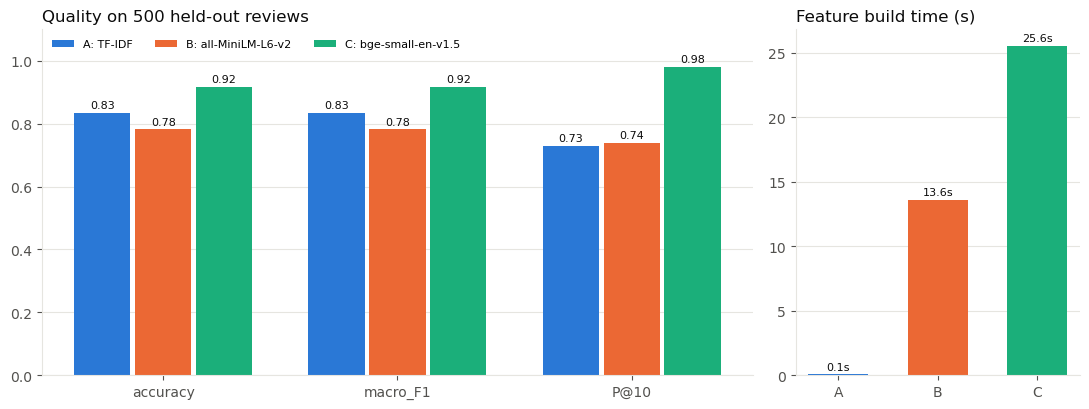

In [10]:
import matplotlib.pyplot as plt
import numpy as np

COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]   # fixed categorical order: A, B, C
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
metrics = ["accuracy", "macro_F1", "P@10"]
models = list(results.index)

fig, (ax, ax_t) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [3, 1.2]})
w = 0.26
x = np.arange(len(metrics))
for i, (m, c) in enumerate(zip(models, COLORS)):
    vals = results.loc[m, metrics].values
    bars = ax.bar(x + (i - 1) * w, vals, w - 0.02, color=c, label=m)
    ax.bar_label(bars, fmt="%.2f", fontsize=8, color=INK, padding=2)
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1.1)
ax.set_title("Quality on 500 held-out reviews", loc="left", color=INK)
ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=3)

t = results["feature_time_s"].values
bars = ax_t.bar(range(len(models)), t, 0.6, color=COLORS)
ax_t.bar_label(bars, fmt="%.1fs", fontsize=8, color=INK, padding=2)
ax_t.set_xticks(range(len(models)), [m.split(":")[0] for m in models])
ax_t.set_title("Feature build time (s)", loc="left", color=INK)

for a in (ax, ax_t):
    a.spines[["top", "right"]].set_visible(False)
    a.spines[["left", "bottom"]].set_color(GRID)
    a.tick_params(colors=MUTED)
    a.yaxis.grid(True, color=GRID, linewidth=0.8)
    a.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Answers

I chose all-MiniLM-L6-v2 as an older, small model and bge-small-en-v1.5 as a newer model designed for finding relevant information. Both models are similar in size. I selected them based on their performance in classification and retrieval tasks listed in MTEB.

The results showed that bge-small-en-v1.5 performed better on both tasks. Using only 1,000 reviews for training, it also performed better than TF-IDF trained on the same number of reviews and TF-IDF trained on the full dataset of 25,000 reviews. However, MiniLM did not outperform TF-IDF when both used 1,000 reviews. This shows that whether embeddings perform better than TF-IDF depends on the model used.

One mistake the AI made was using the old name for the dataset, 'imdb' instead oh 'stanfordnlp/imdb'. Its first report overstated MiniLM's classification performance which I corrected using information from the model card.

One potential risk in a real-world application is truncation. With max_seq_length = 256, the model only processes the beginning of long reviews. This means it might miss important information near the end, such as a positive review that ends with a negative opinion. 


### Notes on the results
- MiniLM falls below TF-IDF on classification. It was trained for general sentence similarity, so it encodes what a review is about more than its sentiment. TF-IDF with Logistic Regression can put weight directly on individual sentiment words.
- Query 9 ("not bad at all..."): TF-IDF and MiniLM both rank a negative review first, because they match "bad" and "expected" and miss the negation. bge-small ranks a positive review first.
- Query 10 ("I expected a great film but it fell flat"): all three models rank a negative review first. TF-IDF gets there partly by luck, by matching "great" and "film". bge's top hit is the closest in meaning ("I was expecting much more from this movie").